In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

In [63]:
df = pd.read_excel("indian_roads_dataset.xlsx")
df

,accident_id,city,state,latitude,longitude,date,time,hour,day_of_week,is_weekend,...,visibility,temperature,traffic_density,cause,accident_severity,vehicles_involved,casualties,is_peak_hour,festival,risk_score
0,0,Pune,Maharashtra,18.680827,73.930388,2023-10-22,05:00:00,5,Sunday,1,...,low,32,high,weather,fatal,2,2,0,NaN,0.85
1,1,Mumbai,Maharashtra,18.817732,72.790846,2023-05-21,04:00:00,4,Sunday,1,...,high,34,low,weather,major,4,3,0,NaN,0.10
2,2,Mumbai,Maharashtra,19.096889,72.819424,2024-07-10,13:00:00,13,Wednesday,0,...,low,21,medium,weather,minor,1,1,0,NaN,0.45
3,3,Chandigarh,Punjab,30.787805,76.847507,2025-03-30,11:00:00,11,Sunday,1,...,low,30,high,distraction,minor,5,2,0,NaN,0.65
4,4,Chennai,Tamil Nadu,12.965155,80.283313,2024-01-25,16:00:00,16,Thursday,0,...,high,24,low,distraction,minor,2,1,0,NaN,0.10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,19995,Bangalore,Karnataka,13.092276,77.599571,2022-09-29,03:00:00,3,Thursday,0,...,high,31,low,distraction,minor,3,2,0,NaN,0.10
19996,19996,Chennai,Tamil Nadu,13.172928,80.157062,2023-11-25,01:00:00,1,Saturday,1,...,high,20,low,distraction,major,4,2,0,NaN,0.10
19997,19997,Chennai,Tamil Nadu,12.997170,80.150724,2022-06-18,15:00:00,15,Saturday,1,...,high,22,low,weather,minor,3,3,0,NaN,0.10
19998,19998,Kolkata,West Bengal,22.454882,88.322213,2023-03-12,04:00:00,4,Sunday,1,...,high,33,low,poor road,minor,1,0,0,NaN,0.10


In [64]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 24 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   accident_id        20000 non-null  int64         
 1   city               20000 non-null  str           
 2   state              20000 non-null  str           
 3   latitude           20000 non-null  float64       
 4   longitude          20000 non-null  float64       
 5   date               20000 non-null  datetime64[us]
 6   time               20000 non-null  object        
 7   hour               20000 non-null  int64         
 8   day_of_week        20000 non-null  str           
 9   is_weekend         20000 non-null  int64         
 10  road_type          20000 non-null  str           
 11  lanes              20000 non-null  int64         
 12  traffic_signal     20000 non-null  int64         
 13  weather            20000 non-null  str           
 14  visibility       

In [65]:
df.columns

Index(['accident_id', 'city', 'state', 'latitude', 'longitude', 'date', 'time',
       'hour', 'day_of_week', 'is_weekend', 'road_type', 'lanes',
       'traffic_signal', 'weather', 'visibility', 'temperature',
       'traffic_density', 'cause', 'accident_severity', 'vehicles_involved',
       'casualties', 'is_peak_hour', 'festival', 'risk_score'],
      dtype='str')

In [66]:
df.describe()

,accident_id,latitude,longitude,date,hour,is_weekend,lanes,traffic_signal,temperature,vehicles_involved,casualties,is_peak_hour,risk_score
count,20000.000000,20000.000000,20000.000000,20000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,9999.500000,20.389207,78.173330,2023-08-22 07:04:48,11.487200,0.286150,3.493950,0.499850,27.579600,2.992000,1.726450,0.247400,0.437585
min,0.000000,12.800172,72.700017,2022-01-01 00:00:00,0.000000,0.000000,1.000000,0.000000,15.000000,1.000000,0.000000,0.000000,0.100000
25%,4999.750000,13.198653,73.997979,2022-10-25 00:00:00,5.000000,0.000000,2.000000,0.000000,21.000000,2.000000,1.000000,0.000000,0.250000
50%,9999.500000,18.812008,77.297000,2023-08-21 00:00:00,12.000000,0.000000,4.000000,0.000000,28.000000,3.000000,1.000000,0.000000,0.450000
75%,14999.250000,28.402467,80.111089,2024-06-21 00:00:00,18.000000,1.000000,5.000000,1.000000,34.000000,4.000000,3.000000,0.000000,0.600000
max,19999.000000,30.799960,88.499861,2025-04-15 00:00:00,23.000000,1.000000,6.000000,1.000000,40.000000,5.000000,5.000000,1.000000,1.000000
std,5773.647028,6.165791,4.485967,NaN,6.945563,0.451972,1.705406,0.500012,7.454746,1.415534,1.489104,0.431512,0.218130


In [67]:
df.shape

(20000, 24)

In [68]:
df.isnull().sum()

accident_id              0
city                     0
state                    0
latitude                 0
longitude                0
date                     0
time                     0
hour                     0
day_of_week              0
is_weekend               0
road_type                0
lanes                    0
traffic_signal           0
weather                  0
visibility               0
temperature              0
traffic_density          0
cause                    0
accident_severity        0
vehicles_involved        0
casualties               0
is_peak_hour             0
festival             19885
risk_score               0
dtype: int64

In [69]:
for col in df.columns:
    print("\n", col)
    print(df[col].value_counts().head(15))


 accident_id
accident_id
0     1
1     1
2     1
3     1
4     1
5     1
6     1
7     1
8     1
9     1
10    1
11    1
12    1
13    1
14    1
Name: count, dtype: int64

 city
city
Chandigarh    2577
Chennai       2575
Kolkata       2559
Pune          2517
Mumbai        2492
Bangalore     2438
Delhi         2433
Hyderabad     2409
Name: count, dtype: int64

 state
state
Maharashtra    5009
Punjab         2577
Tamil Nadu     2575
West Bengal    2559
Karnataka      2438
Delhi          2433
Telangana      2409
Name: count, dtype: int64

 latitude
latitude
30.669447    2
13.052805    2
13.074040    2
30.666974    2
19.025583    2
28.608120    2
12.887308    2
12.815252    2
18.555849    2
12.955431    2
17.367822    2
13.184077    2
28.726555    2
30.780343    2
12.963310    2
Name: count, dtype: int64

 longitude
longitude
72.748749    2
76.842778    2
80.196891    2
88.331370    2
88.232242    2
76.822427    2
76.776371    2
78.390922    2
88.413271    2
76.836003    2
88.368192    2


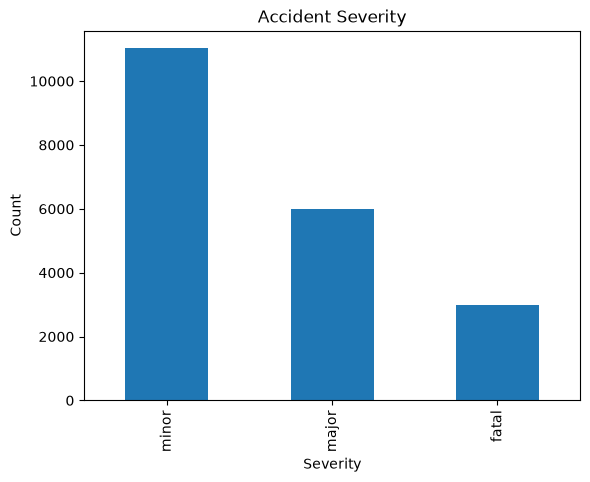

In [70]:
df["accident_severity"].value_counts().plot(kind="bar")
plt.title("Accident Severity")
plt.xlabel("Severity")
plt.ylabel("Count")
plt.show()

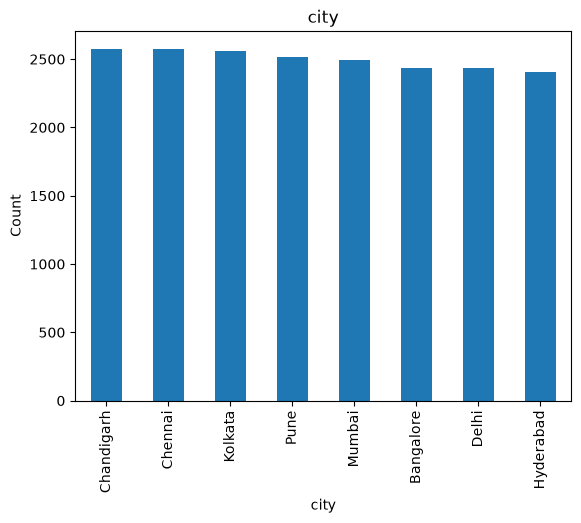

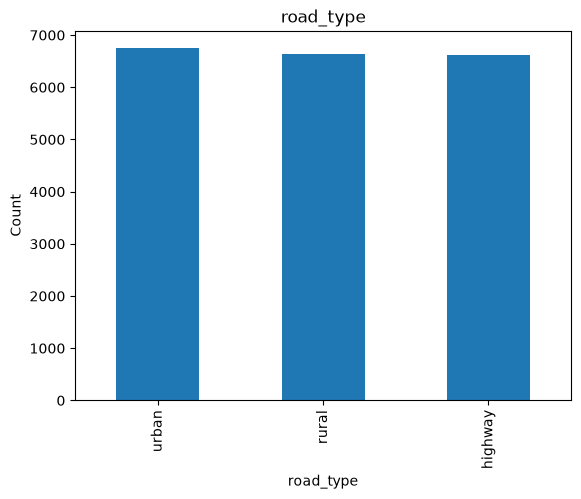

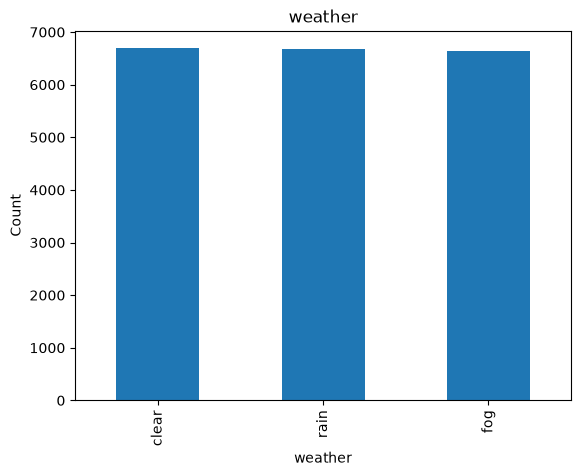

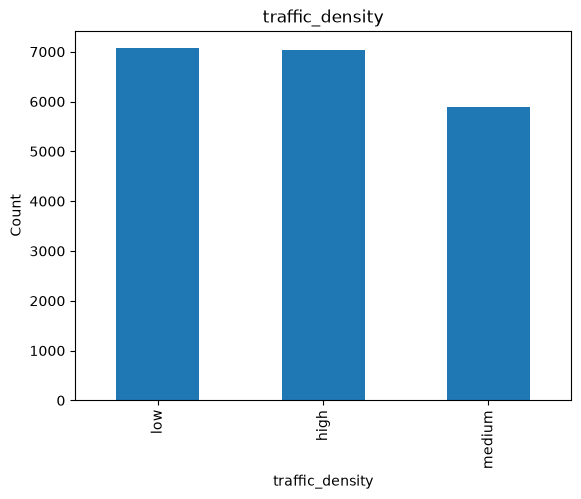

In [71]:
for col in ["city", "road_type", "weather", "traffic_density"]:
    df[col].value_counts().plot(kind="bar")
    plt.title(col)
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()

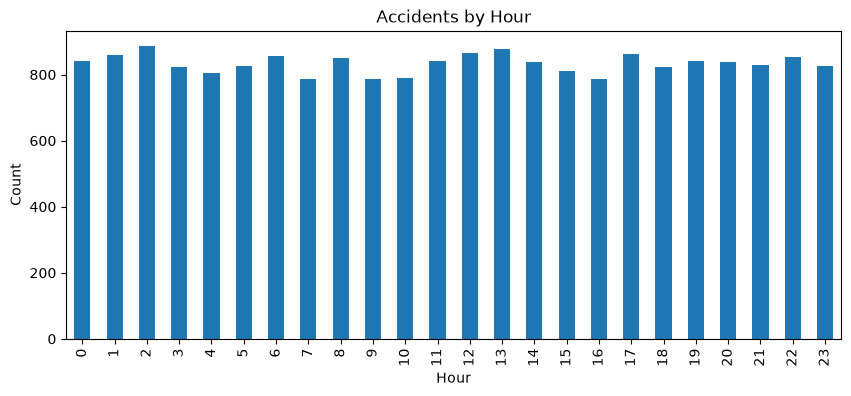

In [72]:
df["hour"].value_counts().sort_index().plot(kind="bar", figsize=(10, 4))
plt.title("Accidents by Hour")
plt.xlabel("Hour")
plt.ylabel("Count")
plt.show()

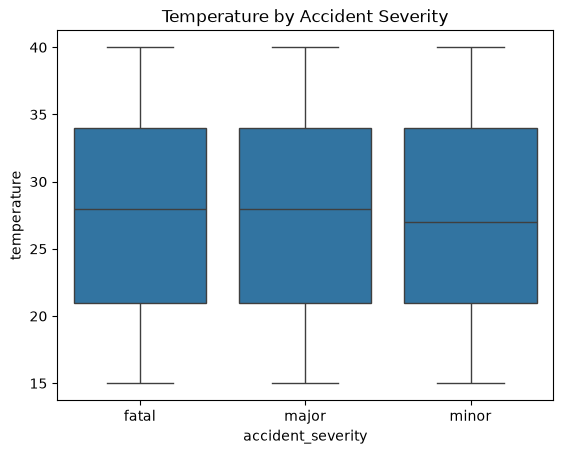

In [73]:
sns.boxplot(data=df, x="accident_severity", y="temperature")
plt.title("Temperature by Accident Severity")
plt.show()

In [74]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

df = df.drop(columns=[
    "accident_id", "state", "date", "time", "cause",
    "vehicles_involved", "casualties", "festival", "risk_score"
])

X = df.drop("accident_severity", axis=1)
y = df["accident_severity"]
X.head()

,city,latitude,longitude,hour,day_of_week,is_weekend,road_type,lanes,traffic_signal,weather,visibility,temperature,traffic_density,is_peak_hour,year,month,hour_sin,hour_cos
0,Pune,18.680827,73.930388,5,Sunday,1,highway,3,1,fog,low,32,high,0,2023,10,0.965926,0.258819
1,Mumbai,18.817732,72.790846,4,Sunday,1,urban,4,0,clear,high,34,low,0,2023,5,0.866025,0.500000
2,Mumbai,19.096889,72.819424,13,Wednesday,0,urban,3,0,fog,low,21,medium,0,2024,7,-0.258819,-0.965926
3,Chandigarh,30.787805,76.847507,11,Sunday,1,urban,1,1,fog,low,30,high,0,2025,3,0.258819,-0.965926
4,Chennai,12.965155,80.283313,16,Thursday,0,highway,3,1,clear,high,24,low,0,2024,1,-0.866025,-0.500000


In [75]:
num_cols = [
    "latitude", "longitude", "hour", "is_weekend", "lanes",
    "traffic_signal", "temperature", "is_peak_hour", "year",
    "month", "hour_sin", "hour_cos"
]
cat_cols = ["city", "day_of_week", "road_type", "weather"]
ord_cols = ["visibility", "traffic_density"]

In [76]:
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

ord_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        categories=[["low", "medium", "high"], ["low", "medium", "high"]],
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

In [77]:
preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
    ("ord", ord_pipe, ord_cols)
])

In [78]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [79]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=42),
    "SVM": SVC(class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

In [80]:
results = []
trained_models = {}

for name, classifier in models.items():
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    trained_models[name] = model

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro F1": f1_score(y_test, y_pred, average="macro")
    })

    print("\n", name)
    print(classification_report(y_test, y_pred, zero_division=0))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

results_df = pd.DataFrame(results).sort_values("Macro F1", ascending=False)
results_df


 Logistic Regression
              precision    recall  f1-score   support

       fatal       0.15      0.36      0.21       597
       major       0.31      0.35      0.33      1198
       minor       0.55      0.30      0.39      2205

    accuracy                           0.33      4000
   macro avg       0.34      0.34      0.31      4000
weighted avg       0.42      0.33      0.35      4000

Confusion Matrix:
[[212 190 195]
 [419 423 356]
 [803 730 672]]

 KNN
              precision    recall  f1-score   support

       fatal       0.11      0.10      0.10       597
       major       0.28      0.27      0.27      1198
       minor       0.54      0.58      0.56      2205

    accuracy                           0.42      4000
   macro avg       0.31      0.32      0.31      4000
weighted avg       0.40      0.42      0.41      4000

Confusion Matrix:
[[  58  178  361]
 [ 161  319  718]
 [ 289  627 1289]]

 Decision Tree
              precision    recall  f1-score   support

  

,Model,Accuracy,Macro F1
2,Decision Tree,0.40600,0.324910
1,KNN,0.41650,0.314495
0,Logistic Regression,0.32675,0.311256
4,Random Forest,0.45675,0.308358
3,SVM,0.31800,0.296783
5,Gradient Boosting,0.55025,0.240429


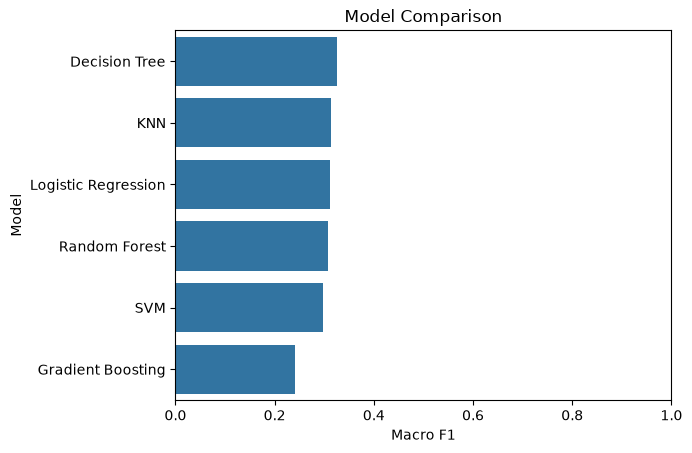

In [81]:
sns.barplot(data=results_df, x="Macro F1", y="Model")
plt.title("Model Comparison")
plt.xlim(0, 1)
plt.show()

In [82]:
best_model = results_df.iloc[0]
print("Best model:", best_model["Model"])
print("Accuracy:", round(best_model["Accuracy"], 3))
print("Macro F1:", round(best_model["Macro F1"], 3))

Best model: Decision Tree
Accuracy: 0.406
Macro F1: 0.325


In [83]:
results_df.to_csv("model_comparison_results.csv", index=False)

In [84]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

print("Baseline Accuracy:", accuracy_score(y_test, baseline_pred))
print("Baseline Macro F1:", f1_score(y_test, baseline_pred, average="macro"))
print(classification_report(y_test, baseline_pred, zero_division=0))

Baseline Accuracy: 0.55125
Baseline Macro F1: 0.2369057211925866
              precision    recall  f1-score   support

       fatal       0.00      0.00      0.00       597
       major       0.00      0.00      0.00      1198
       minor       0.55      1.00      0.71      2205

    accuracy                           0.55      4000
   macro avg       0.18      0.33      0.24      4000
weighted avg       0.30      0.55      0.39      4000



In [85]:
weighted_models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced", max_iter=1000
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        class_weight="balanced", random_state=42
    ),
    "SVM": SVC(
        class_weight="balanced"
    )
}

weighted_results = []

for name, classifier in weighted_models.items():
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    report = classification_report(
        y_test, y_pred, output_dict=True, zero_division=0
    )

    weighted_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro F1": f1_score(y_test, y_pred, average="macro"),
        "Fatal Recall": report["fatal"]["recall"],
        "Fatal F1": report["fatal"]["f1-score"]
    })

weighted_results_df = pd.DataFrame(weighted_results)
weighted_results_df.sort_values("Macro F1", ascending=False)

,Model,Accuracy,Macro F1,Fatal Recall,Fatal F1
1,Decision Tree,0.40600,0.324910,0.139028,0.135289
0,Logistic Regression,0.32675,0.311256,0.355109,0.208764
2,Random Forest,0.45675,0.308358,0.035176,0.052632
3,SVM,0.31800,0.296783,0.313233,0.191992


In [86]:
for name, model in weighted_models.items():
    print(name, "->", model.get_params().get("class_weight"))

Logistic Regression -> balanced
Decision Tree -> balanced
Random Forest -> balanced
SVM -> balanced


In [87]:
for name, classifier in weighted_models.items():
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    print(f"\n{name}")
    print(pd.Series(predictions).value_counts())


Logistic Regression
fatal    1434
major    1343
minor    1223
Name: count, dtype: int64

Decision Tree
minor    2137
major    1233
fatal     630
Name: count, dtype: int64

Random Forest
minor    2753
major    1046
fatal     201
Name: count, dtype: int64

SVM
fatal    1351
minor    1348
major    1301
Name: count, dtype: int64


In [88]:
weighted_results = []

for name, classifier in weighted_models.items():
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    report = classification_report(
        y_test, y_pred,
        output_dict=True,
        zero_division=0
    )

    weighted_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro F1": f1_score(y_test, y_pred, average="macro"),
        "Fatal Precision": report["fatal"]["precision"],
        "Fatal Recall": report["fatal"]["recall"],
        "Fatal F1": report["fatal"]["f1-score"]
    })

weighted_results_df = pd.DataFrame(weighted_results)
weighted_results_df.sort_values("Macro F1", ascending=False).round(3)

,Model,Accuracy,Macro F1,Fatal Precision,Fatal Recall,Fatal F1
1,Decision Tree,0.406,0.325,0.132,0.139,0.135
0,Logistic Regression,0.327,0.311,0.148,0.355,0.209
2,Random Forest,0.457,0.308,0.104,0.035,0.053
3,SVM,0.318,0.297,0.138,0.313,0.192


In [89]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(15))

print("\nColumn data types:")
print(df.dtypes)

print("\nTarget distribution:")
print(df["accident_severity"].value_counts())

Dataset shape: (20000, 19)

Missing values:
city                 0
latitude             0
longitude            0
hour                 0
day_of_week          0
is_weekend           0
road_type            0
lanes                0
traffic_signal       0
weather              0
visibility           0
temperature          0
traffic_density      0
accident_severity    0
is_peak_hour         0
dtype: int64

Column data types:
city                     str
latitude             float64
longitude            float64
hour                   int64
day_of_week              str
is_weekend             int64
road_type                str
lanes                  int64
traffic_signal         int64
weather                  str
visibility               str
temperature            int64
traffic_density          str
accident_severity        str
is_peak_hour           int64
year                   int32
month                  int32
hour_sin             float64
hour_cos             float64
dtype: object

Target distr

In [90]:
print("Current dataset columns:")
print(df.columns.tolist())

print("\nFeatures used for training:")
print(X_train.columns.tolist())

print("\nNumber of training features:", X_train.shape[1])
print("Number of test rows:", X_test.shape[0])

Current dataset columns:
['city', 'latitude', 'longitude', 'hour', 'day_of_week', 'is_weekend', 'road_type', 'lanes', 'traffic_signal', 'weather', 'visibility', 'temperature', 'traffic_density', 'accident_severity', 'is_peak_hour', 'year', 'month', 'hour_sin', 'hour_cos']

Features used for training:
['city', 'latitude', 'longitude', 'hour', 'day_of_week', 'is_weekend', 'road_type', 'lanes', 'traffic_signal', 'weather', 'visibility', 'temperature', 'traffic_density', 'is_peak_hour', 'year', 'month', 'hour_sin', 'hour_cos']

Number of training features: 18
Number of test rows: 4000


In [91]:
print("Preprocessor configuration:")
print(preprocessor)

print("\nPreprocessor transformers:")
print(preprocessor.transformers)

Preprocessor configuration:
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['latitude', 'longitude', 'hour', 'is_weekend',
                                  'lanes', 'traffic_signal', 'temperature',
                                  'is_peak_hour', 'year', 'month', 'hour_sin',
                                  'hour_cos']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['city', 'day_of_week', 'road_type',
    

In [92]:
print("Visibility values:")
print(df["visibility"].value_counts(dropna=False))

print("\nTraffic density values:")
print(df["traffic_density"].value_counts(dropna=False))

print("\nNumerical feature summary:")
print(df[[
    "latitude", "longitude", "hour", "lanes",
    "temperature", "year", "month"
]].describe())

Visibility values:
visibility
low       9987
high      6690
medium    3323
Name: count, dtype: int64

Traffic density values:
traffic_density
low       7067
high      7034
medium    5899
Name: count, dtype: int64

Numerical feature summary:
           latitude     longitude          hour         lanes   temperature  \
count  20000.000000  20000.000000  20000.000000  20000.000000  20000.000000   
mean      20.389207     78.173330     11.487200      3.493950     27.579600   
std        6.165791      4.485967      6.945563      1.705406      7.454746   
min       12.800172     72.700017      0.000000      1.000000     15.000000   
25%       13.198653     73.997979      5.000000      2.000000     21.000000   
50%       18.812008     77.297000     12.000000      4.000000     28.000000   
75%       28.402467     80.111089     18.000000      5.000000     34.000000   
max       30.799960     88.499861     23.000000      6.000000     40.000000   

               year        month  
count  20000

In [93]:
comparison = []

for name, classifier in models.items():
    # Original model
    original = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])
    original.fit(X_train, y_train)
    original_pred = original.predict(X_test)

    comparison.append({
        "Model": name,
        "Approach": "Original",
        "Accuracy": accuracy_score(y_test, original_pred),
        "Macro F1": f1_score(y_test, original_pred, average="macro"),
        "Fatal Recall": classification_report(
            y_test, original_pred,
            output_dict=True, zero_division=0
        )["fatal"]["recall"]
    })

for name, classifier in weighted_models.items():
    weighted = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])
    weighted.fit(X_train, y_train)
    weighted_pred = weighted.predict(X_test)

    comparison.append({
        "Model": name,
        "Approach": "Balanced",
        "Accuracy": accuracy_score(y_test, weighted_pred),
        "Macro F1": f1_score(y_test, weighted_pred, average="macro"),
        "Fatal Recall": classification_report(
            y_test, weighted_pred,
            output_dict=True, zero_division=0
        )["fatal"]["recall"]
    })

comparison_df = pd.DataFrame(comparison)
comparison_df.round(3)

,Model,Approach,Accuracy,Macro F1,Fatal Recall
0,Logistic Regression,Original,0.327,0.311,0.355
1,KNN,Original,0.416,0.314,0.097
2,Decision Tree,Original,0.406,0.325,0.139
3,SVM,Original,0.318,0.297,0.313
4,Random Forest,Original,0.457,0.308,0.035
5,Gradient Boosting,Original,0.550,0.240,0.000
6,Logistic Regression,Balanced,0.327,0.311,0.355
7,Decision Tree,Balanced,0.406,0.325,0.139
8,Random Forest,Balanced,0.457,0.308,0.035
9,SVM,Balanced,0.318,0.297,0.313


In [94]:
final_results = results_df.copy()

final_results = final_results.sort_values(
    "Macro F1", ascending=False
).reset_index(drop=True)

final_results["Accuracy"] = final_results["Accuracy"].round(4)
final_results["Macro F1"] = final_results["Macro F1"].round(4)

final_results.to_csv("final_model_comparison.csv", index=False)

display(final_results)
print("\nSaved as final_model_comparison.csv")

,Model,Accuracy,Macro F1
0,Decision Tree,0.4060,0.3249
1,KNN,0.4165,0.3145
2,Logistic Regression,0.3268,0.3113
3,Random Forest,0.4568,0.3084
4,SVM,0.3180,0.2968
5,Gradient Boosting,0.5502,0.2404



Saved as final_model_comparison.csv
